In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create an e-commerce dataset
data = {
    "order_id": list(range(1001, 1021)),

    "order_date": [
        "2026-01-05", "2026-01-12", "2026-01-18",
        "2026-02-03", "2026-02-11", "2026-02-20",
        "2026-03-02", "2026-03-09", "2026-03-21",
        "2026-04-04", "2026-04-15", "2026-04-23",
        "2026-05-06", "2026-05-14", "2026-05-26",
        "2026-06-02", "2026-06-13", "2026-06-22",
        "2026-06-25", "2026-06-28"
    ],

    "product": [
        "Laptop", "Smartphone", "Headphones", "Smartwatch",
        "Laptop", "Keyboard", "Smartphone", "Headphones",
        "Monitor", "Laptop", "Smartwatch", "Keyboard",
        "Smartphone", "Monitor", "Headphones", "Laptop",
        "Keyboard", "Smartwatch", "Smartphone", "Monitor"
    ],

    "category": [
        "Electronics", "Electronics", "Accessories", "Wearables",
        "Electronics", "Accessories", "Electronics", "Accessories",
        "Electronics", "Electronics", "Wearables", "Accessories",
        "Electronics", "Electronics", "Accessories", "Electronics",
        "Accessories", "Wearables", "Electronics", "Electronics"
    ],

    "region": [
        "South", "North", "West", "East", "South",
        "West", "North", "South", "East", "West",
        "North", "East", "South", "West", "North",
        "East", "South", "West", "North", "East"
    ],

    "units_sold": [
        2, 3, 5, 2, 1, 4, 2, 6, 2, 1,
        3, 5, 2, 3, 4, 2, 6, 3, 1, 2
    ],

    "unit_price": [
        55000, 25000, 2000, 8000, 55000,
        1500, 25000, 2000, 18000, 55000,
        8000, 1500, 25000, 18000, 2000,
        55000, 1500, 8000, 25000, 18000
    ],

    "discount_percent": [
        10, 5, 0, 10, 5, 0, 10, 5, 0, 10,
        5, 0, 10, 5, 0, 5, 10, 0, 5, 10
    ]
}

df = pd.DataFrame(data)

# Convert order_date into datetime format
df["order_date"] = pd.to_datetime(df["order_date"])

# Calculate revenue after discount
df["revenue"] = (
    df["units_sold"] * df["unit_price"]
    * (1 - df["discount_percent"] / 100)
)

print(df.head())
print("Dataset created successfully!")

   order_id order_date     product     category region  units_sold  \
0      1001 2026-01-05      Laptop  Electronics  South           2   
1      1002 2026-01-12  Smartphone  Electronics  North           3   
2      1003 2026-01-18  Headphones  Accessories   West           5   
3      1004 2026-02-03  Smartwatch    Wearables   East           2   
4      1005 2026-02-11      Laptop  Electronics  South           1   

   unit_price  discount_percent  revenue  
0       55000                10  99000.0  
1       25000                 5  71250.0  
2        2000                 0  10000.0  
3        8000                10  14400.0  
4       55000                 5  52250.0  
Dataset created successfully!


In [32]:
# Display first five rows
print(df.head())

# Display last five rows
print(df.tail())

# Dataset dimensions: rows and columns
print("Shape:", df.shape)

# Column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check again
print("Duplicates after:", df.duplicated().sum())

   order_id order_date     product     category region  units_sold  \
0      1001 2026-01-05      Laptop  Electronics  South           2   
1      1002 2026-01-12  Smartphone  Electronics  North           3   
2      1003 2026-01-18  Headphones  Accessories   West           5   
3      1004 2026-02-03  Smartwatch    Wearables   East           2   
4      1005 2026-02-11      Laptop  Electronics  South           1   

   unit_price  discount_percent  revenue  
0       55000                10  99000.0  
1       25000                 5  71250.0  
2        2000                 0  10000.0  
3        8000                10  14400.0  
4       55000                 5  52250.0  
    order_id order_date     product     category region  units_sold  \
15      1016 2026-06-02      Laptop  Electronics   East           2   
16      1017 2026-06-13    Keyboard  Accessories  South           6   
17      1018 2026-06-22  Smartwatch    Wearables   West           3   
18      1019 2026-06-25  Smartphone  

In [33]:
# Summary statistics for numerical columns
print(df.describe())

# Mean revenue per order
mean_revenue = df["revenue"].mean()

print("Average revenue per order: ₹", round(mean_revenue, 2))

# Total revenue
print("Total revenue: ₹", round(df["revenue"].sum(), 2))

         order_id           order_date  units_sold    unit_price  \
count    20.00000                   20   20.000000     20.000000   
mean   1010.50000  2026-04-06 16:48:00    2.950000  20425.000000   
min    1001.00000  2026-01-05 00:00:00    1.000000   1500.000000   
25%    1005.75000  2026-02-17 18:00:00    2.000000   2000.000000   
50%    1010.50000  2026-04-09 12:00:00    2.500000  18000.000000   
75%    1015.25000  2026-05-27 18:00:00    4.000000  25000.000000   
max    1020.00000  2026-06-28 00:00:00    6.000000  55000.000000   
std       5.91608                  NaN    1.571958  19787.206792   

       discount_percent        revenue  
count          20.00000      20.000000  
mean            5.25000   36107.500000  
min             0.00000    6000.000000  
25%             0.00000   11050.000000  
50%             5.00000   28200.000000  
75%            10.00000   49950.000000  
max            10.00000  104500.000000  
std             4.12789   29244.546388  
Average revenue pe

In [34]:
# Number of orders containing each product
print("Product occurrence counts:")
print(df["product"].value_counts())

# Total units sold per product
product_sales = df.groupby("product")["units_sold"].sum()

print("\nTotal units sold per product:")
print(product_sales.sort_values(ascending=False))

# Total revenue per product
product_revenue = (
    df.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue per product:")
print(product_revenue)

Product occurrence counts:
product
Laptop        4
Smartphone    4
Headphones    3
Smartwatch    3
Keyboard      3
Monitor       3
Name: count, dtype: int64

Total units sold per product:
product
Headphones    15
Keyboard      15
Smartwatch     8
Smartphone     8
Monitor        7
Laptop         6
Name: units_sold, dtype: int64

Revenue per product:
product
Laptop        305250.0
Smartphone    185000.0
Monitor       119700.0
Smartwatch     61200.0
Headphones     29400.0
Keyboard       21600.0
Name: revenue, dtype: float64


In [35]:
regional_sales = df.groupby("region").agg( total_revenue=("revenue", "sum"), average_order_revenue=("revenue", "mean"), order_count=("order_id", "count"),
    total_units=("units_sold", "sum")
)

# Sort regions by total revenue
regional_sales = regional_sales.sort_values(
    by="total_revenue",
    ascending=False
)

print(regional_sales.round(2))

        total_revenue  average_order_revenue  order_count  total_units
region                                                                
South        215750.0                43150.0            5           17
East         194800.0                38960.0            5           13
North        170800.0                34160.0            5           13
West         140800.0                28160.0            5           16


In [36]:
# Select numerical sales columns
numeric_columns = [
    "units_sold",
    "unit_price",
    "discount_percent",
    "revenue"
]

# Correlation matrix
correlation_matrix = df[numeric_columns].corr()

print("Correlation matrix:")
print(correlation_matrix.round(2))

# Correlation between units sold and revenue
correlation = df["units_sold"].corr(df["revenue"])

print(
    "\nCorrelation between units sold and revenue:",
    round(correlation, 3)
)

Correlation matrix:
                  units_sold  unit_price  discount_percent  revenue
units_sold              1.00       -0.73             -0.36    -0.55
unit_price             -0.73        1.00              0.43     0.85
discount_percent       -0.36        0.43              1.00     0.36
revenue                -0.55        0.85              0.36     1.00

Correlation between units sold and revenue: -0.554


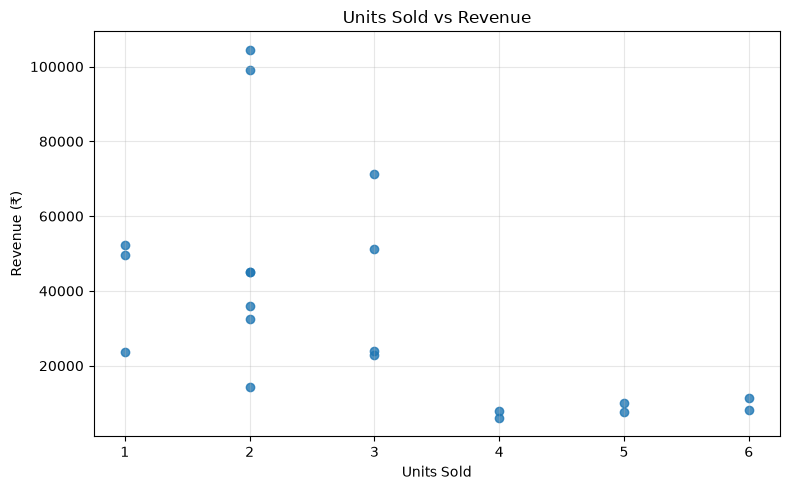

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["units_sold"],
    df["revenue"],
    alpha=0.8
)

plt.title("Units Sold vs Revenue")
plt.xlabel("Units Sold")
plt.ylabel("Revenue (₹)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Monthly revenue:
month
2026-01    180250.0
2026-02     72650.0
2026-03     92400.0
2026-04     79800.0
2026-05    104300.0
2026-06    192750.0
Freq: M, Name: revenue, dtype: float64


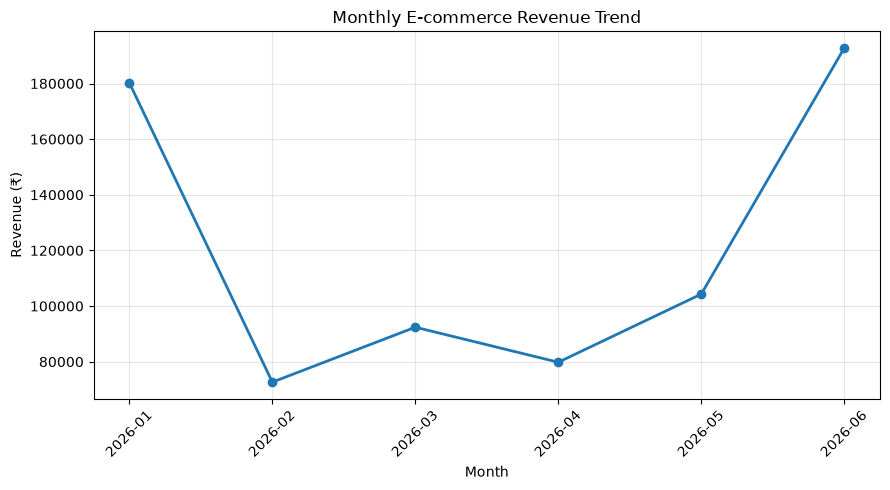

In [38]:
# Extract year and month
df["month"] = df["order_date"].dt.to_period("M")

# Calculate monthly revenue
monthly_revenue = df.groupby("month")["revenue"].sum()

print("Monthly revenue:")
print(monthly_revenue)

# Plot monthly revenue trend
plt.figure(figsize=(9, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly E-commerce Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
top_5_orders = df.nlargest(5, "revenue")[
    [
        "order_id",
        "order_date",
        "product",
        "region",
        "units_sold",
        "unit_price",
        "discount_percent",
        "revenue"
    ]
]

print("Top 5 revenue-generating orders:")
print(top_5_orders.to_string(index=False))

Top 5 revenue-generating orders:
 order_id order_date    product region  units_sold  unit_price  discount_percent  revenue
     1016 2026-06-02     Laptop   East           2       55000                 5 104500.0
     1001 2026-01-05     Laptop  South           2       55000                10  99000.0
     1002 2026-01-12 Smartphone  North           3       25000                 5  71250.0
     1005 2026-02-11     Laptop  South           1       55000                 5  52250.0
     1014 2026-05-14    Monitor   West           3       18000                 5  51300.0


In [40]:
df[[
    "order_id",
    "order_date",
    "product",
    "category",
    "region",
    "units_sold",
    "unit_price",
    "discount_percent",
    "revenue"
]]

,order_id,order_date,product,category,region,units_sold,unit_price,discount_percent,revenue
0,1001,2026-01-05,Laptop,Electronics,South,2,55000,10,99000.0
1,1002,2026-01-12,Smartphone,Electronics,North,3,25000,5,71250.0
2,1003,2026-01-18,Headphones,Accessories,West,5,2000,0,10000.0
3,1004,2026-02-03,Smartwatch,Wearables,East,2,8000,10,14400.0
4,1005,2026-02-11,Laptop,Electronics,South,1,55000,5,52250.0
5,1006,2026-02-20,Keyboard,Accessories,West,4,1500,0,6000.0
6,1007,2026-03-02,Smartphone,Electronics,North,2,25000,10,45000.0
7,1008,2026-03-09,Headphones,Accessories,South,6,2000,5,11400.0
8,1009,2026-03-21,Monitor,Electronics,East,2,18000,0,36000.0
9,1010,2026-04-04,Laptop,Electronics,West,1,55000,10,49500.0


In [41]:
# Monthly revenue summary using groupby
monthly_summary = df.groupby(
    df["order_date"].dt.to_period("M")
).agg(
    total_orders=("order_id", "count"),
    total_units_sold=("units_sold", "sum"),
    total_revenue=("revenue", "sum"),
    average_revenue=("revenue", "mean")
)

print(monthly_summary)

            total_orders  total_units_sold  total_revenue  average_revenue
order_date                                                                
2026-01                3                10       180250.0     60083.333333
2026-02                3                 7        72650.0     24216.666667
2026-03                3                10        92400.0     30800.000000
2026-04                3                 9        79800.0     26600.000000
2026-05                3                 9       104300.0     34766.666667
2026-06                5                14       192750.0     38550.000000


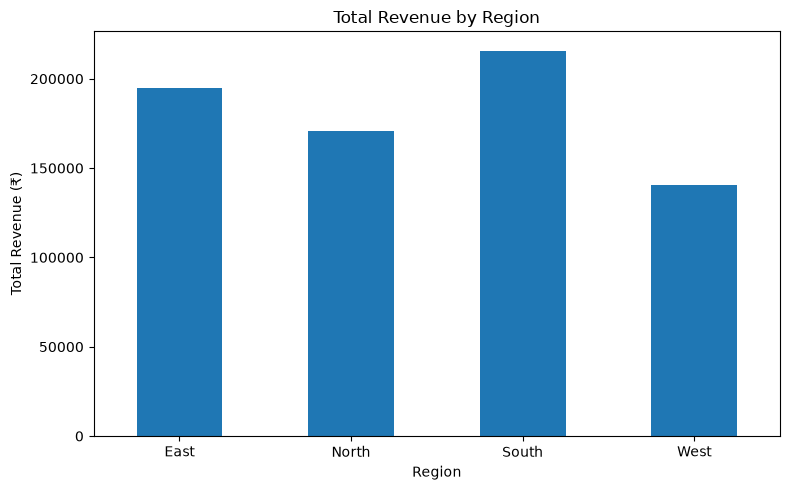

In [42]:
# Calculate total revenue by region
region_revenue = df.groupby("region")["revenue"].sum()

# Create bar chart using plot()
region_revenue.plot(kind="bar", figsize=(8, 5))

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

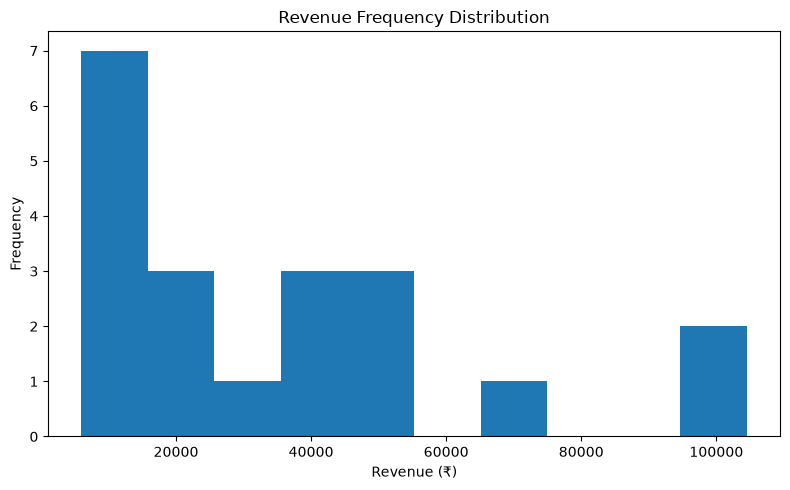

In [43]:
# Histogram of revenue frequency
df["revenue"].plot(kind="hist", bins=10, figsize=(8, 5))

plt.title("Revenue Frequency Distribution")
plt.xlabel("Revenue (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [44]:
product_quantity = df.groupby("product")["units_sold"].sum()

print("Highest-selling product:")
print(product_quantity.idxmax())

print("Total units sold:")
print(product_quantity.max())

Highest-selling product:
Headphones
Total units sold:
15
